# AI Employment in the USA: Data Visualisation

| | |
|---|---|
| **Module** | Data Visualisation and Communication |
| **Assessment** | CA1 (40%) |
| **Lecturer** | Taufique Ahmed |
| **Student** | Matheus Leandro (2024657) |
| **Programme** | BSc (Hons) in Computing in IT |
| **Submission date** | [TO FILL] |
| **Video (4 min)** | [TO FILL: Google Drive link, shared with "Anyone with the link"] |
| **GitHub repository** | https://github.com/MatheusFerreiraL/dvc-ca1-ai-employment |


## Contents

1. Introduction
2. Data loading and preparation
3. Defining AI-related occupations
4. Visualisations of May 2023 data
5. Challenge: AI employment trends over time
6. Limitations
7. Summary of findings
8. References
9. Appendix: AI use

## 1. Introduction

_To be completed._

In [1]:
# Libraries used in this notebook
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Same look for every static chart
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 2. Data loading and preparation

The data comes from the Occupational Employment and Wage Statistics (OEWS) survey of the U.S. Bureau of Labor Statistics (BLS). I used the "All data" file for May 2023 (`all_data_M_2023.xlsx`), downloaded from the BLS OEWS tables page (U.S. Bureau of Labor Statistics, 2024). The file is not included in this repository, and the README explains how to download it.

### 2.1 Loading the file

The file is read with `pd.read_excel`. It is large (about 80 MB), so this cell takes around one minute to run. Some numeric columns, such as `TOT_EMP` and `A_MEAN`, also contain special codes like `*` and `**` when a value is not available. Because of this, pandas reads those columns as text. Section 2.2 converts them to numbers.

In [2]:
# Read the May 2023 "All data" file (this takes about one minute)
raw_2023 = pd.read_excel("data/oesm23all/all_data_M_2023.xlsx")

# Number of rows and columns
print("Rows:", raw_2023.shape[0])
print("Columns:", raw_2023.shape[1])

Rows: 413327
Columns: 32


In [3]:
raw_2023.head(3)

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN


Each row is the estimate for one occupation, in one area, at one industry level. The columns used most in this notebook are:

| Column | Meaning |
|---|---|
| `AREA_TYPE` | 1 = U.S., 2 = state, 3 = U.S. territory, 4 = metropolitan area, 6 = non-metropolitan area |
| `I_GROUP` | Industry level: cross-industry (all industries together), sector, 3-digit to 6-digit NAICS |
| `OCC_CODE`, `OCC_TITLE`, `O_GROUP` | SOC occupation code, title and level (total, major, minor, broad, detailed) |
| `TOT_EMP` | Total employment, rounded to the nearest 10 (self-employed excluded) |
| `A_MEAN`, `A_MEDIAN`, `A_PCT10` … `A_PCT90` | Annual wages: mean, median and percentiles (US dollars) |
| `LOC_QUOTIENT` | Share of the occupation in an area compared with its share in the whole U.S. |

The next cell counts the rows at each level.

In [4]:
# Number of rows at each level of geography, industry and occupation
for col in ["AREA_TYPE", "I_GROUP", "O_GROUP"]:
    print(raw_2023[col].value_counts())
    print()

AREA_TYPE
1    177501
4    149591
6     48559
2     36643
3      1033
Name: count, dtype: int64

I_GROUP
cross-industry               237229
4-digit                       83350
3-digit                       39097
sector                        16376
5-digit                       15518
4-digit, ownership             9856
cross-industry, ownership      5628
3-digit, ownership             4561
6-digit                        1712
Name: count, dtype: int64

O_GROUP
detailed    306185
broad        62131
minor        23374
major        20601
total         1036
Name: count, dtype: int64



The file mixes several levels in the same table. There is one national area, 51 states (including the District of Columbia), 3 territories, 396 metropolitan areas and 136 non-metropolitan areas. Industries and occupations also appear at several levels. If rows from different levels are added together, the same workers are counted more than once. For this reason, Section 2.3 selects one level at a time.

### 2.2 Converting the numeric columns

Some numeric columns use special codes instead of a number. The "Field Descriptions" sheet of the same Excel file explains them:

| Code | Meaning |
|---|---|
| `*` | Wage estimate not available |
| `**` | Employment estimate not available |
| `#` | Wage is $239,200 or more per year ($115.00 or more per hour) |
| `~` | Less than 0.5% of establishments reported the occupation (column `PCT_RPT`, not used here) |

To use these columns in charts, they must be numbers. I used `pd.to_numeric` with `errors="coerce"`. This function was not covered in class. I used it because I could not find a function in the class materials that does the same job in one step. It converts every value that is a valid number and turns the codes into missing values (`NaN`). Missing values are then left out of sums, means and plots. Only the columns used in this notebook are converted.

In [5]:
# Columns with numbers that also contain codes such as *, ** and #
num_cols = ["TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "A_MEAN",
            "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"]

# Turn each column into numbers; the codes become missing values (NaN)
for col in num_cols:
    raw_2023[col] = pd.to_numeric(raw_2023[col], errors="coerce")

# Number of missing values in each converted column
raw_2023[num_cols].isnull().sum()

TOT_EMP          11598
JOBS_1000       181134
LOC_QUOTIENT    181134
A_MEAN            5352
A_PCT10           5353
A_PCT25           5815
A_MEDIAN          7474
A_PCT75          10606
A_PCT90          17844
dtype: int64

After the conversion, `TOT_EMP` has 11,598 missing values (the `**` code) and `A_MEAN` has 5,352 (the `*` and `#` codes). `JOBS_1000` and `LOC_QUOTIENT` have many more missing values (181,134). Most of them (177,501) are the national rows, which are empty for these two columns because they compare an area with the whole U.S.; the other 3,633 are `**` codes. `A_PCT90` has the most missing wage values (17,844), because the top 10% of wages in well-paid occupations often reaches the $239,200 limit (`#`). This is a limitation, because in those rows the real wage is above the limit, so the highest wages are left out. Section 6 comes back to this point.

### 2.3 Selecting one level of data

As shown in Section 2.1, the same workers appear in several rows. To avoid counting them twice, I made two tables, each with only one level of geography, industry and occupation:

- `national`: the whole U.S. (`AREA_TYPE` 1), all industries together (`I_GROUP` "cross-industry") and single occupations (`O_GROUP` "detailed"). This table is used for most charts.
- `state`: the same, but for each state (`AREA_TYPE` 2). This table is used for the map.

In [6]:
# National level, all industries together, single (detailed) occupations
national = raw_2023[(raw_2023["AREA_TYPE"] == 1) &
                    (raw_2023["I_GROUP"] == "cross-industry") &
                    (raw_2023["O_GROUP"] == "detailed")]

# Each occupation should appear only once
print("Occupations:", len(national))
print("Duplicated occupation codes:", national["OCC_CODE"].duplicated().sum())

Occupations: 831
Duplicated occupation codes: 0


In [7]:
# Check: the detailed occupations should add up to the "All Occupations" total
total_row = raw_2023[(raw_2023["AREA_TYPE"] == 1) &
                     (raw_2023["I_GROUP"] == "cross-industry") &
                     (raw_2023["O_GROUP"] == "total")]

print("All Occupations (BLS total):", total_row["TOT_EMP"].sum())
print("Sum of detailed occupations:", national["TOT_EMP"].sum())

All Occupations (BLS total): 151853870.0
Sum of detailed occupations: 151853170.0


In [8]:
# State level, all industries together, single (detailed) occupations
state = raw_2023[(raw_2023["AREA_TYPE"] == 2) &
                 (raw_2023["I_GROUP"] == "cross-industry") &
                 (raw_2023["O_GROUP"] == "detailed")]

print("Rows:", len(state))
print("States:", len(state["AREA_TITLE"].unique()))

Rows: 35470
States: 51


The `national` table has 831 occupations and no duplicated codes. Its employment adds up to 151,853,170, which is only 700 less than the "All Occupations" total given by BLS (151,853,870). The small gap comes from rounding, because BLS rounds each employment figure to the nearest 10. This confirms that the filter does not count workers twice. The `state` table has 35,470 rows for 51 areas (the 50 states and the District of Columbia).

## 3. Defining AI-related occupations

The OEWS data uses the 2018 Standard Occupational Classification (SOC). This system has no occupation called "AI engineer" or "machine learning engineer", so people who work on AI are counted inside other occupations. In the full list of SOC definitions, the words "artificial intelligence" do not appear at all, and "machine learning" appears only once, in the definition of Data Scientists (U.S. Bureau of Labor Statistics, 2020).

For this reason, I defined "AI employment" as a group of eight SOC occupations. I split them into the three areas named in the brief: AI, Data Science and Software Development. Each choice is based on the official SOC definition of the occupation.

| Group | SOC code | Occupation | Reason for including it |
|---|---|---|---|
| AI research | 15-1221 | Computer and Information Research Scientists | The closest occupation to AI research: they do basic research in computer science and design new solutions for hardware and software problems |
| Data Science | 15-2051 | Data Scientists | The only definition that names machine learning and natural language processing |
| Data Science | 15-2041 | Statisticians | Develop and apply statistical methods to analyse data; machine learning is based on these methods |
| Data Science | 15-2031 | Operations Research Analysts | Use mathematical models and data to support decisions, and may develop decision support software |
| Software Development | 15-1252 | Software Developers | Design and build software, which includes the systems where AI models are used |
| Software Development | 15-1251 | Computer Programmers | Write and test the code of computer applications |
| Software Development | 15-1253 | Software Quality Assurance Analysts and Testers | Test software and record its defects, so they work on the same products as developers |
| Software Development | 15-1254 | Web Developers | Build websites and web applications, including the databases and interfaces behind them |

This definition has a limitation. Not every worker in these occupations works on AI, and some AI workers are counted in other occupations (for example, "Computer Occupations, All Other"). The group is therefore a proxy for AI employment, not an exact count. Section 6 discusses this again.

To mark the eight occupations, I wrote a dictionary with the SOC code as the key and the group as the value. Then I used `.map()` to add a `GROUP` column to a copy of the `national` table. Occupations that are not in the dictionary get a missing value, so `.dropna(subset=["GROUP"])` removes them and leaves only the eight AI-related occupations. The `subset` option makes `dropna` look only at the `GROUP` column, because other columns (for example `A_PCT90`) also have missing values.

In [9]:
# The eight AI-related occupations: SOC code and group
ai_groups = {
    "15-1221": "AI research",
    "15-2051": "Data Science",
    "15-2041": "Data Science",
    "15-2031": "Data Science",
    "15-1252": "Software Development",
    "15-1251": "Software Development",
    "15-1253": "Software Development",
    "15-1254": "Software Development"
}

# Add the group of each occupation (other occupations get NaN)
ai_jobs = national.copy()
ai_jobs["GROUP"] = ai_jobs["OCC_CODE"].map(ai_groups)

# Keep only the eight AI-related occupations
ai_jobs = ai_jobs.dropna(subset=["GROUP"])

# Main columns, from the largest employment to the smallest
ai_jobs[["GROUP", "OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN", "A_MEDIAN"]].sort_values("TOT_EMP", ascending=False)

,GROUP,OCC_CODE,OCC_TITLE,TOT_EMP,A_MEAN,A_MEDIAN
149,Software Development,15-1252,Software Developers,1656880.0,138110.0,132270.0
150,Software Development,15-1253,Software Quality Assurance Analysts and Testers,203040.0,108460.0,101800.0
165,Data Science,15-2051,Data Scientists,192710.0,119040.0,108020.0
148,Software Development,15-1251,Computer Programmers,120370.0,107750.0,99700.0
161,Data Science,15-2031,Operations Research Analysts,117880.0,95600.0,83640.0
151,Software Development,15-1254,Web Developers,85350.0,95570.0,84960.0
138,AI research,15-1221,Computer and Information Research Scientists,35210.0,157160.0,145080.0
163,Data Science,15-2041,Statisticians,29950.0,109190.0,104110.0


In [10]:
# Total employment of each group
group_emp = ai_jobs.groupby("GROUP")["TOT_EMP"].sum()
print(group_emp)
print()

# AI-related employment compared with all occupations in the U.S.
print("AI-related employment:", ai_jobs["TOT_EMP"].sum())
print("Share of all U.S. employment (%):", round(ai_jobs["TOT_EMP"].sum() / national["TOT_EMP"].sum() * 100, 2))

GROUP
AI research               35210.0
Data Science             340540.0
Software Development    2065640.0
Name: TOT_EMP, dtype: float64

AI-related employment: 2441390.0
Share of all U.S. employment (%): 1.61


The eight occupations employ 2,441,390 people, which is 1.61% of all employment in the U.S. in May 2023. Software Development is by far the largest group, with 2,065,640 workers (about 85% of the total), and Software Developers alone account for 1,656,880. Data Science has 340,540 workers, and AI research is the smallest group, with only 35,210. However, AI research has the highest mean annual wage of the eight occupations ($157,160). Because of this difference in size, the AI research group would be almost invisible next to Software Developers on one common scale, so the scale of each chart in Section 4 has to be chosen with care.

## 4. Visualisations of May 2023 data

_To be completed._

### 4.1 Visualisation 1: Horizontal bar chart of employment by occupation

This first chart compares the size of the eight AI-related occupations. The same three colours are used for the groups in every chart of this notebook, so the reader can follow each group from one chart to the next.

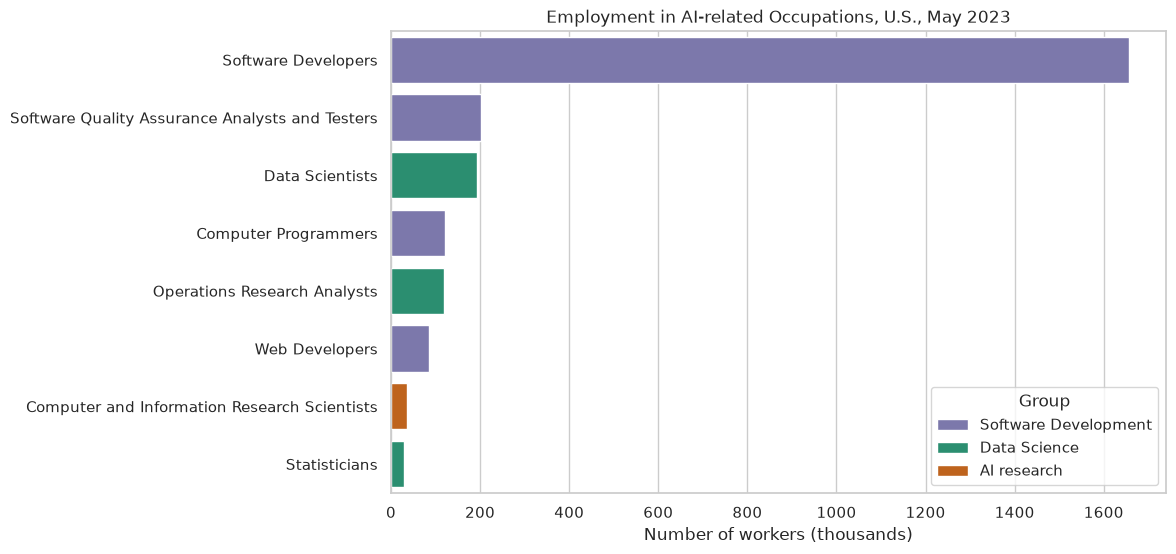

In [11]:
# One colour per group, used again in the next charts
group_colours = {
    "AI research": "#d95f02",
    "Data Science": "#1b9e77",
    "Software Development": "#7570b3"
}

# Employment in thousands, so the axis numbers are short
ai_jobs["EMP_THOUSANDS"] = ai_jobs["TOT_EMP"] / 1000

# Largest occupation at the top
emp_sorted = ai_jobs.sort_values("TOT_EMP", ascending=False)

sns.barplot(data=emp_sorted, x="EMP_THOUSANDS", y="OCC_TITLE", hue="GROUP", palette=group_colours)
plt.title("Employment in AI-related Occupations, U.S., May 2023")
plt.xlabel("Number of workers (thousands)")
plt.ylabel("")
plt.legend(title="Group")
plt.show()

- **Objective:** To compare how many people work in each of the eight AI-related occupations, and to see which group is the largest.
- **Why this plot:** The occupation is a categorical variable and employment is a numerical value, so a bar chart is the natural way to compare them. I used horizontal bars because the occupation names are long and would overlap on a vertical x-axis. The bars are sorted from the largest to the smallest, and the colour shows the group. I used `sns.barplot` instead of `sns.countplot` (used in class) because the data already has one total per occupation, so nothing needs to be counted. I kept a linear scale: a logarithmic scale would show the small bars better, but it would hide how big the real differences are.
- **Learning:** Software Developers are by far the largest occupation, with 1,656,880 workers. This is about 68% of all AI-related employment and more than twice the other seven occupations together (784,510). Software Quality Assurance Analysts and Testers (203,040) and Data Scientists (192,710) come next, with very similar sizes. The occupations closest to AI research and statistics are the smallest: Computer and Information Research Scientists have 35,210 workers and Statisticians 29,950. This means that in 2023 most AI-related jobs were about building and testing software, and only a small number were in research.

### 4.2 Visualisation 2

_To be completed._

### 4.3 Visualisation 3

_To be completed._

### 4.4 Visualisation 4

_To be completed._

### 4.5 Visualisation 5

_To be completed._

### 4.6 Visualisation 6

_To be completed._

## 5. Challenge: AI employment trends over time

_To be completed._

## 6. Limitations

_To be completed._

## 7. Summary of findings

_To be completed._

## 8. References

_To be completed._

## 9. Appendix: AI use

_To be completed._